# 0. CONFIGURACIÓN Y CARGA BASE

In [1]:
# ==============================================================================
# CELDA 0 RÁPIDA: CARGA BASE (TRAIN 2008 & EVAL 2009 Q1)
# ==============================================================================
import os, shutil, orjson
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

if "BASE_DRIVE" not in globals():
  from google.colab import drive

  drive.mount("/content/drive")
  BASE_DRIVE = "/content/drive/MyDrive/TFG/data"

DRIVE_TRAIN = os.path.join(BASE_DRIVE, "medication_request_2008.jsonl")
DRIVE_EVAL = os.path.join(BASE_DRIVE, "medication_request_2009_q1.jsonl")

LOCAL_TRAIN = "/content/medication_request_2008.jsonl"
LOCAL_EVAL = "/content/medication_request_2009_q1.jsonl"

# Si no están en disco local de Colab, los copiamos una sola vez desde Drive
if not os.path.exists(LOCAL_TRAIN) and os.path.exists(DRIVE_TRAIN):
  print("⏳ Copiando Train (2008) a disco local de Colab...")
  shutil.copy2(DRIVE_TRAIN, LOCAL_TRAIN)

if not os.path.exists(LOCAL_EVAL) and os.path.exists(DRIVE_EVAL):
  print("⏳ Copiando Eval (2009 Q1) a disco local de Colab...")
  shutil.copy2(DRIVE_EVAL, LOCAL_EVAL)

DIR_FIGURAS = os.path.join(BASE_DRIVE, "figuras_eda")
os.makedirs(DIR_FIGURAS, exist_ok=True)


def cargar_dataframe_eda(ruta, split_label):
  filas = []
  with open(ruta, "rb") as f:
    for i, line in enumerate(f, start=1):
      if not line.strip():
        continue
      r = orjson.loads(line)
      dval = r.get("dose_value")
      dunit = (r.get("dose_unit") or "").strip()
      try:
        dval_num = float(dval) if dval is not None and dval != "" else np.nan
      except (TypeError, ValueError):
        dval_num = np.nan

      auth = r.get("authoredOn") or ""
      mes = (
          int(auth[5:7])
          if len(auth) >= 7 and auth[5:7].isdigit()
          else np.nan
      )

      filas.append((
          split_label,
          r.get("IdMedicationRequest"),
          r.get("encounter_id") or "",
          r.get("patient_id") or "",
          (r.get("medication_name") or "unknown").strip(),
          auth,
          mes,
          dval_num,
          dunit,
      ))
      if i % 500_000 == 0:
        print(f"   [{split_label}] Leídas {i:,} filas...")

  df = pd.DataFrame(
      filas,
      columns=[
          "split",
          "id",
          "encounter_id",
          "patient_id",
          "medication_name",
          "authoredOn",
          "mes",
          "dose_value",
          "dose_unit",
      ],
  )
  # Conversión vectorizada de fechas (mucho más rápida que fila a fila)
  df["ts"] = pd.to_datetime(df["authoredOn"], format="ISO8601", utc=True, errors="coerce")
  return df


def guardar_fig(nombre_archivo):
  ruta_fig = os.path.join(DIR_FIGURAS, nombre_archivo)
  plt.tight_layout()
  plt.savefig(ruta_fig, bbox_inches="tight")
  plt.show()
  print(f"💾 Guardada: {ruta_fig}")


print("⏳ Cargando datasets...")
df_train = cargar_dataframe_eda(LOCAL_TRAIN, "train")
df_eval = cargar_dataframe_eda(LOCAL_EVAL, "eval")
print(f"✅ Listo -> Train: {len(df_train):,} | Eval: {len(df_eval):,}")

Mounted at /content/drive
⏳ Copiando Train (2008) a disco local de Colab...
⏳ Copiando Eval (2009 Q1) a disco local de Colab...
⏳ Cargando datasets...
   [train] Leídas 500,000 filas...
   [train] Leídas 1,000,000 filas...
   [train] Leídas 1,500,000 filas...
   [train] Leídas 2,000,000 filas...
✅ Listo -> Train: 2,074,742 | Eval: 243,119


# 1. ÓRDENES POR MES

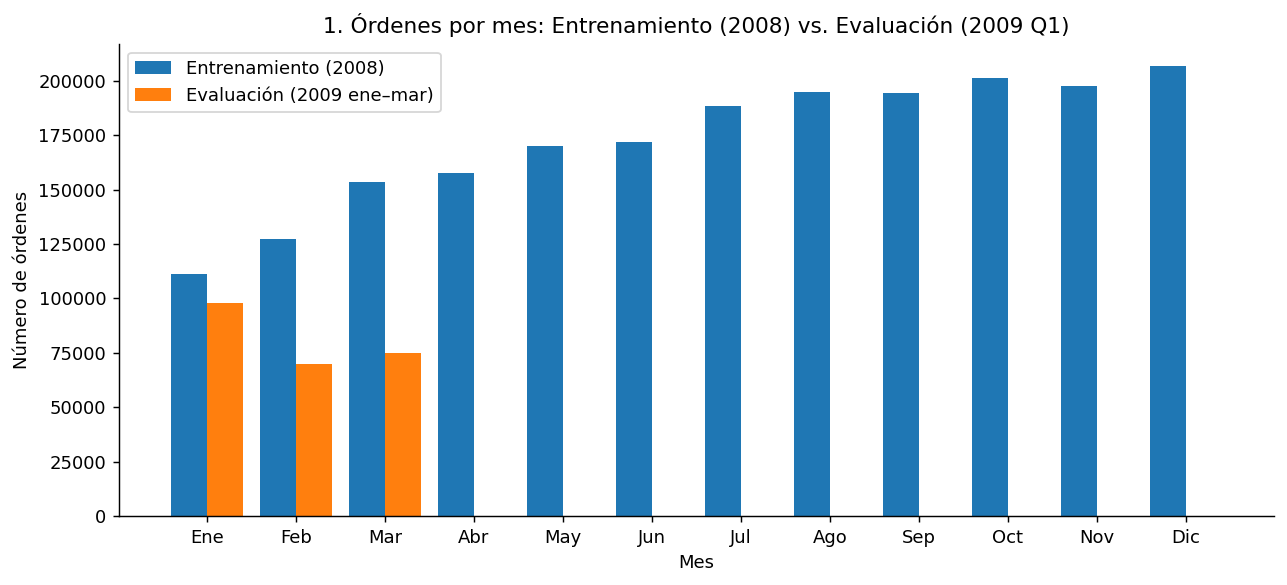

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/01_ordenes_por_mes.png


In [2]:
# ==============================================================================
# GRÁFICA 1: ÓRDENES POR MES (TRAIN 2008 VS EVAL 2009 ENE-MAR)
# ==============================================================================
meses = np.arange(1, 13)
etiquetas_mes = [
    "Ene",
    "Feb",
    "Mar",
    "Abr",
    "May",
    "Jun",
    "Jul",
    "Ago",
    "Sep",
    "Oct",
    "Nov",
    "Dic",
]
cnt_tr_mes = [int((df_train["mes"] == m).sum()) for m in meses]
cnt_ev_mes = [int((df_eval["mes"] == m).sum()) for m in meses]

x = np.arange(len(meses))
ancho = 0.4
plt.figure(figsize=(10, 4.6))
plt.bar(
    x - ancho / 2,
    cnt_tr_mes,
    width=ancho,
    label="Entrenamiento (2008)",
    color="#1f77b4",
)
plt.bar(
    x + ancho / 2,
    cnt_ev_mes,
    width=ancho,
    label="Evaluación (2009 ene–mar)",
    color="#ff7f0e",
)
plt.xticks(x, etiquetas_mes)
plt.xlabel("Mes")
plt.ylabel("Número de órdenes")
plt.title("1. Órdenes por mes: Entrenamiento (2008) vs. Evaluación (2009 Q1)")
plt.legend()
guardar_fig("01_ordenes_por_mes.png")

En entrenamiento (2008) el volumen de órdenes crece progresivamente de enero a diciembre, como era de esperar por cómo MIMIC fija el ancla temporal. Mientras que la evaluación (2009 Q1) concentra su actividad en los tres primeros meses con un volumen menor, acorde a su menor duración.

# 2. CONCENTRACIÓN DE FÁRMACOS

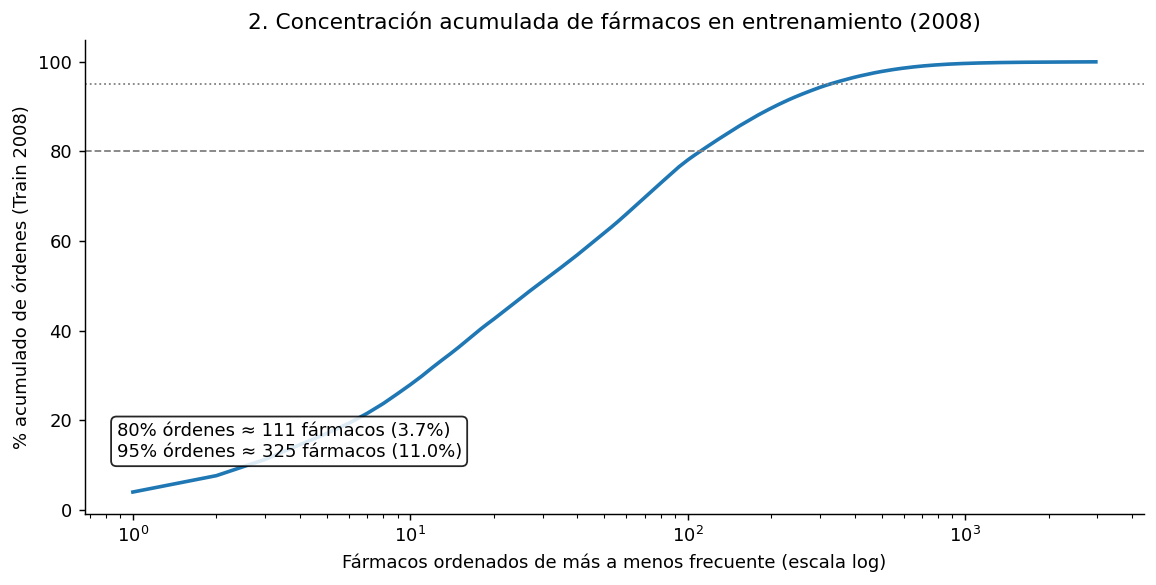

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/02_concentracion_farmacos.png


In [3]:
# ==============================================================================
# GRÁFICA 2: CONCENTRACIÓN ACUMULADA DE FÁRMACOS (LOG-X, TRAIN 2008)
# ==============================================================================
vc_tr = df_train["medication_name"].value_counts()
cum_pct_tr = (vc_tr.cumsum() / len(df_train)) * 100.0
ranks = np.arange(1, len(vc_tr) + 1)

n_80 = int(np.searchsorted(cum_pct_tr.values, 80.0) + 1)
n_95 = int(np.searchsorted(cum_pct_tr.values, 95.0) + 1)

plt.figure(figsize=(9, 4.6))
plt.plot(ranks, cum_pct_tr.values, color="#1f77b4", linewidth=2)
plt.xscale("log")
plt.axhline(80, color="gray", linestyle="--", linewidth=1)
plt.axhline(95, color="gray", linestyle=":", linewidth=1)
plt.xlabel("Fármacos ordenados de más a menos frecuente (escala log)")
plt.ylabel("% acumulado de órdenes (Train 2008)")
plt.title("2. Concentración acumulada de fármacos en entrenamiento (2008)")
plt.text(
    0.03,
    0.12,
    f"80% órdenes ≈ {n_80} fármacos ({n_80/len(vc_tr)*100:.1f}%)\n95% órdenes ≈"
    f" {n_95} fármacos ({n_95/len(vc_tr)*100:.1f}%)",
    transform=plt.gca().transAxes,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
)
guardar_fig("02_concentracion_farmacos.png")

Las órdenes de 2008 están muy concentradas en pocos fármacos: unos 111 medicamentos (3,7 %) acumulan cerca del 80 % de las órdenes y unos 325 (11,0 %) alcanzan el 95 %, quedando el resto de fármacos como mucho menos frecuentes.

# 3. ÓRDENES POR FÁRMACO

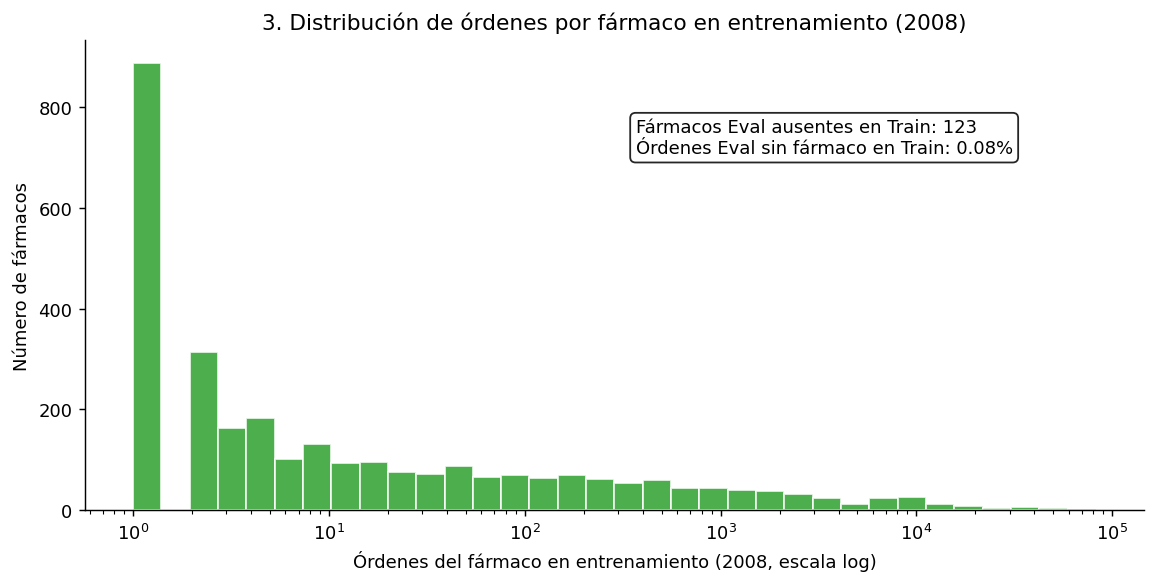

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/03_ordenes_por_farmaco.png


In [4]:
# ==============================================================================
# GRÁFICA 3: HISTOGRAMA DE ÓRDENES POR FÁRMACO (LOG-X, TRAIN 2008)
# ==============================================================================
no_vistos_set = set(df_eval["medication_name"].unique()) - set(vc_tr.index)
ordenes_eval_no_vistas = int(
    df_eval["medication_name"].isin(no_vistos_set).sum()
)
pct_eval_no_vistas = ordenes_eval_no_vistas / len(df_eval) * 100.0

bins_log = np.logspace(0, np.log10(vc_tr.max()), 35)
plt.figure(figsize=(9, 4.6))
plt.hist(
    vc_tr.values,
    bins=bins_log,
    color="#2ca02c",
    edgecolor="white",
    alpha=0.85,
)
plt.xscale("log")
plt.xlabel("Órdenes del fármaco en entrenamiento (2008, escala log)")
plt.ylabel("Número de fármacos")
plt.title("3. Distribución de órdenes por fármaco en entrenamiento (2008)")
plt.text(
    0.52,
    0.76,
    f"Fármacos Eval ausentes en Train: {len(no_vistos_set)}\nÓrdenes Eval"
    f" sin fármaco en Train: {pct_eval_no_vistas:.2f}%",
    transform=plt.gca().transAxes,
    bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
)
guardar_fig("03_ordenes_por_farmaco.png")

Muchos fármacos en 2008 tienen muy pocas órdenes y cuesta sacar un buen perfil de ellos, para entrenar el modelo trataremos de afinar bien los fármacos frecuentes (que en la gráfica anterior hemos visto que están presentes en la mayoría de recetas) y usar reglas más sencillas en los fármacos con menos número de prescripciones.

Además, podemos observar que en 2009 Q1 hay 123 fármacos nuevos, pero apenas suman el 0,08 % de las recetas. Por lo tanto la mayoría que vamos a evaluar lo hemos visto en el entrenamiento

# 4. COBERTURA DE LA DOSIS

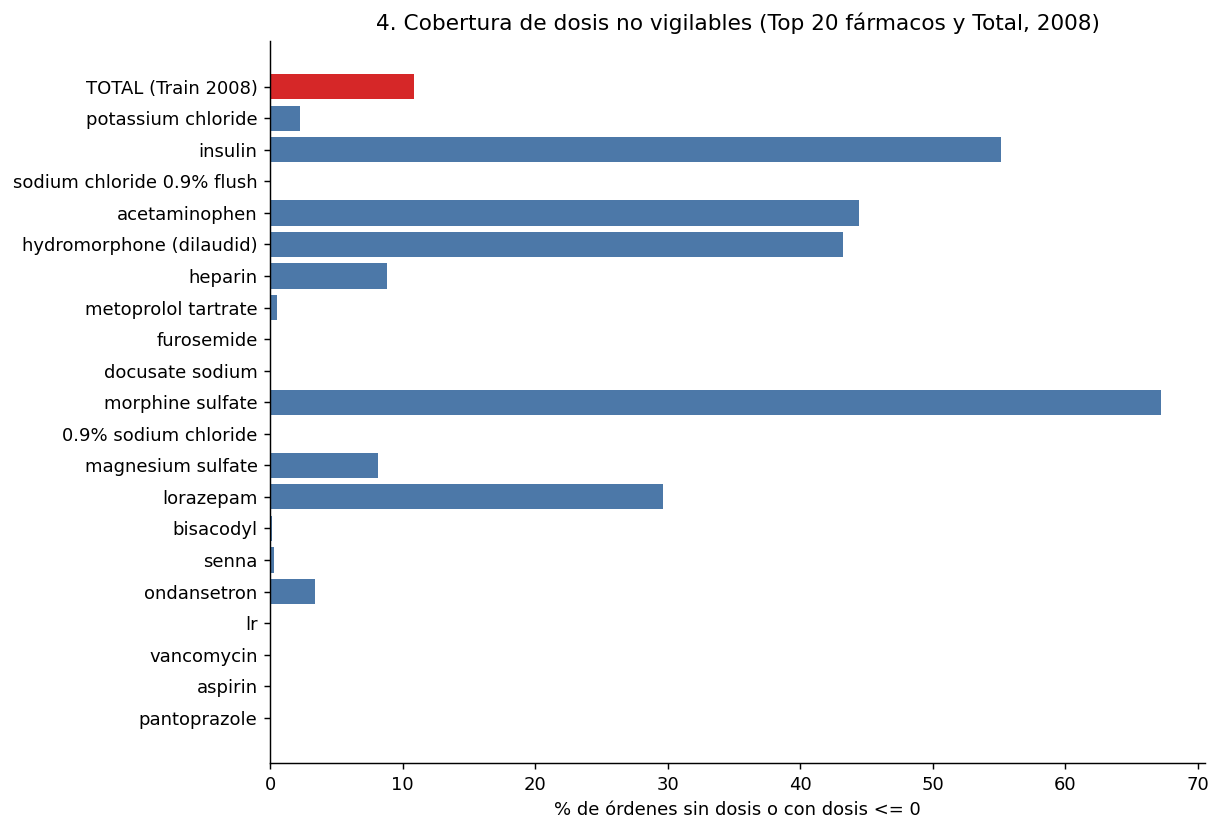

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/04_cobertura_dosis.png


In [5]:
# ==============================================================================
# GRÁFICA 4: COBERTURA DE DOSIS NO VIGILABLES (TOP 20 + TOTAL, TRAIN 2008)
# ==============================================================================
df_tr_cov = df_train.copy()
df_tr_cov["sin_dosis_valida"] = (
    df_tr_cov["dose_value"].isna()
    | (df_tr_cov["dose_value"] <= 0)
    | (df_tr_cov["dose_unit"].str.len() == 0)
)

top20_meds = list(vc_tr.head(20).index)
filas_cov = []
for m in reversed(top20_meds):
  sub = df_tr_cov[df_tr_cov["medication_name"] == m]
  filas_cov.append((m, sub["sin_dosis_valida"].mean() * 100.0))
filas_cov.append(
    ("TOTAL (Train 2008)", df_tr_cov["sin_dosis_valida"].mean() * 100.0)
)

labels_cov = [x[0] for x in filas_cov]
vals_cov = [x[1] for x in filas_cov]
colores_cov = [
    "#d62728" if lbl.startswith("TOTAL") else "#4c78a8" for lbl in labels_cov
]

plt.figure(figsize=(9.5, 6.5))
plt.barh(labels_cov, vals_cov, color=colores_cov)
plt.xlabel("% de órdenes sin dosis o con dosis <= 0")
plt.title("4. Cobertura de dosis no vigilables (Top 20 fármacos y Total, 2008)")
guardar_fig("04_cobertura_dosis.png")

 Alrededor del 10,8 % de las órdenes de 2008 no tiene dosis válida o tiene dosis <= 0, y el problema destaca en fármacos como morphine sulfate, insulin, acetaminophen, hydromorphone (dilaudid) y lorazepam, donde vigilar solo la dosis numérica será difícil.

# 5. UNIDADES POR FÁRMACO

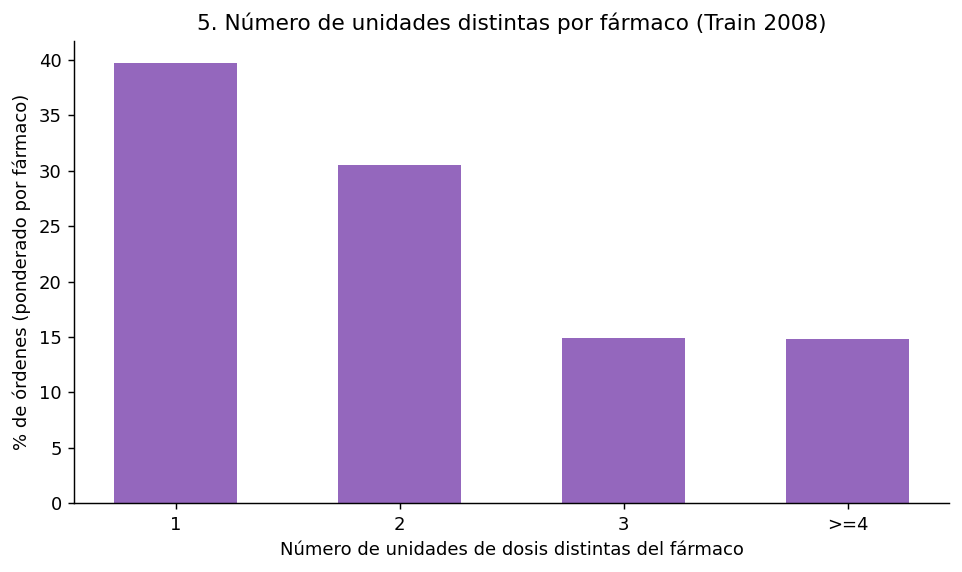

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/05_unidades_por_farmaco.png


In [6]:
# ==============================================================================
# GRÁFICA 5: NÚMERO DE UNIDADES DISTINTAS POR FÁRMACO (PONDERADO POR ÓRDENES)
# ==============================================================================
df_tr_valid_u = df_tr_cov[~df_tr_cov["sin_dosis_valida"]]
n_unidades_por_med = (
    df_tr_valid_u.groupby("medication_name")["dose_unit"]
    .nunique()
    .apply(lambda u: str(u) if u <= 3 else ">=4")
)
mapa_u_ord = df_train["medication_name"].map(n_unidades_por_med).fillna("0")
mask_u = mapa_u_ord != "0"

cats_u = ["1", "2", "3", ">=4"]
pct_u = [
    (mapa_u_ord[mask_u] == c).sum() / mask_u.sum() * 100.0 for c in cats_u
]

plt.figure(figsize=(7.5, 4.5))
plt.bar(cats_u, pct_u, color="#9467bd", width=0.55)
plt.xlabel("Número de unidades de dosis distintas del fármaco")
plt.ylabel("% de órdenes (ponderado por fármaco)")
plt.title("5. Número de unidades distintas por fármaco (Train 2008)")
guardar_fig("05_unidades_por_farmaco.png")

Cerca del 40 % de las órdenes corresponden a fármacos que emplean una única unidad de dosis, mientras que alrededor del 60 % restante pertenece a fármacos con dos o más unidades distintas (incluyendo casi un 30 % con tres o cuatro o más), por lo que hay que tener en cuenta la unidad al analizar la dosis

# 6. DOSIS DE FÁRMACOS TÍPICOS

ℹ️ Mapeo fármacos típicos Gráfica 6: {'acetaminophen': 'acetaminophen', 'hydromorphone (dilaudid)': 'hydromorphone (dilaudid)', 'morphine sulfate': 'morphine sulfate', 'lorazepam': 'lorazepam', 'heparin': 'heparin', 'warfarin': 'warfarin', 'insulin': 'insulin', 'vancomycin': 'vancomycin', 'furosemide': 'furosemide', 'metoprolol tartrate': 'metoprolol tartrate', 'potassium chloride': 'potassium chloride', 'prednisone': 'prednisone'}


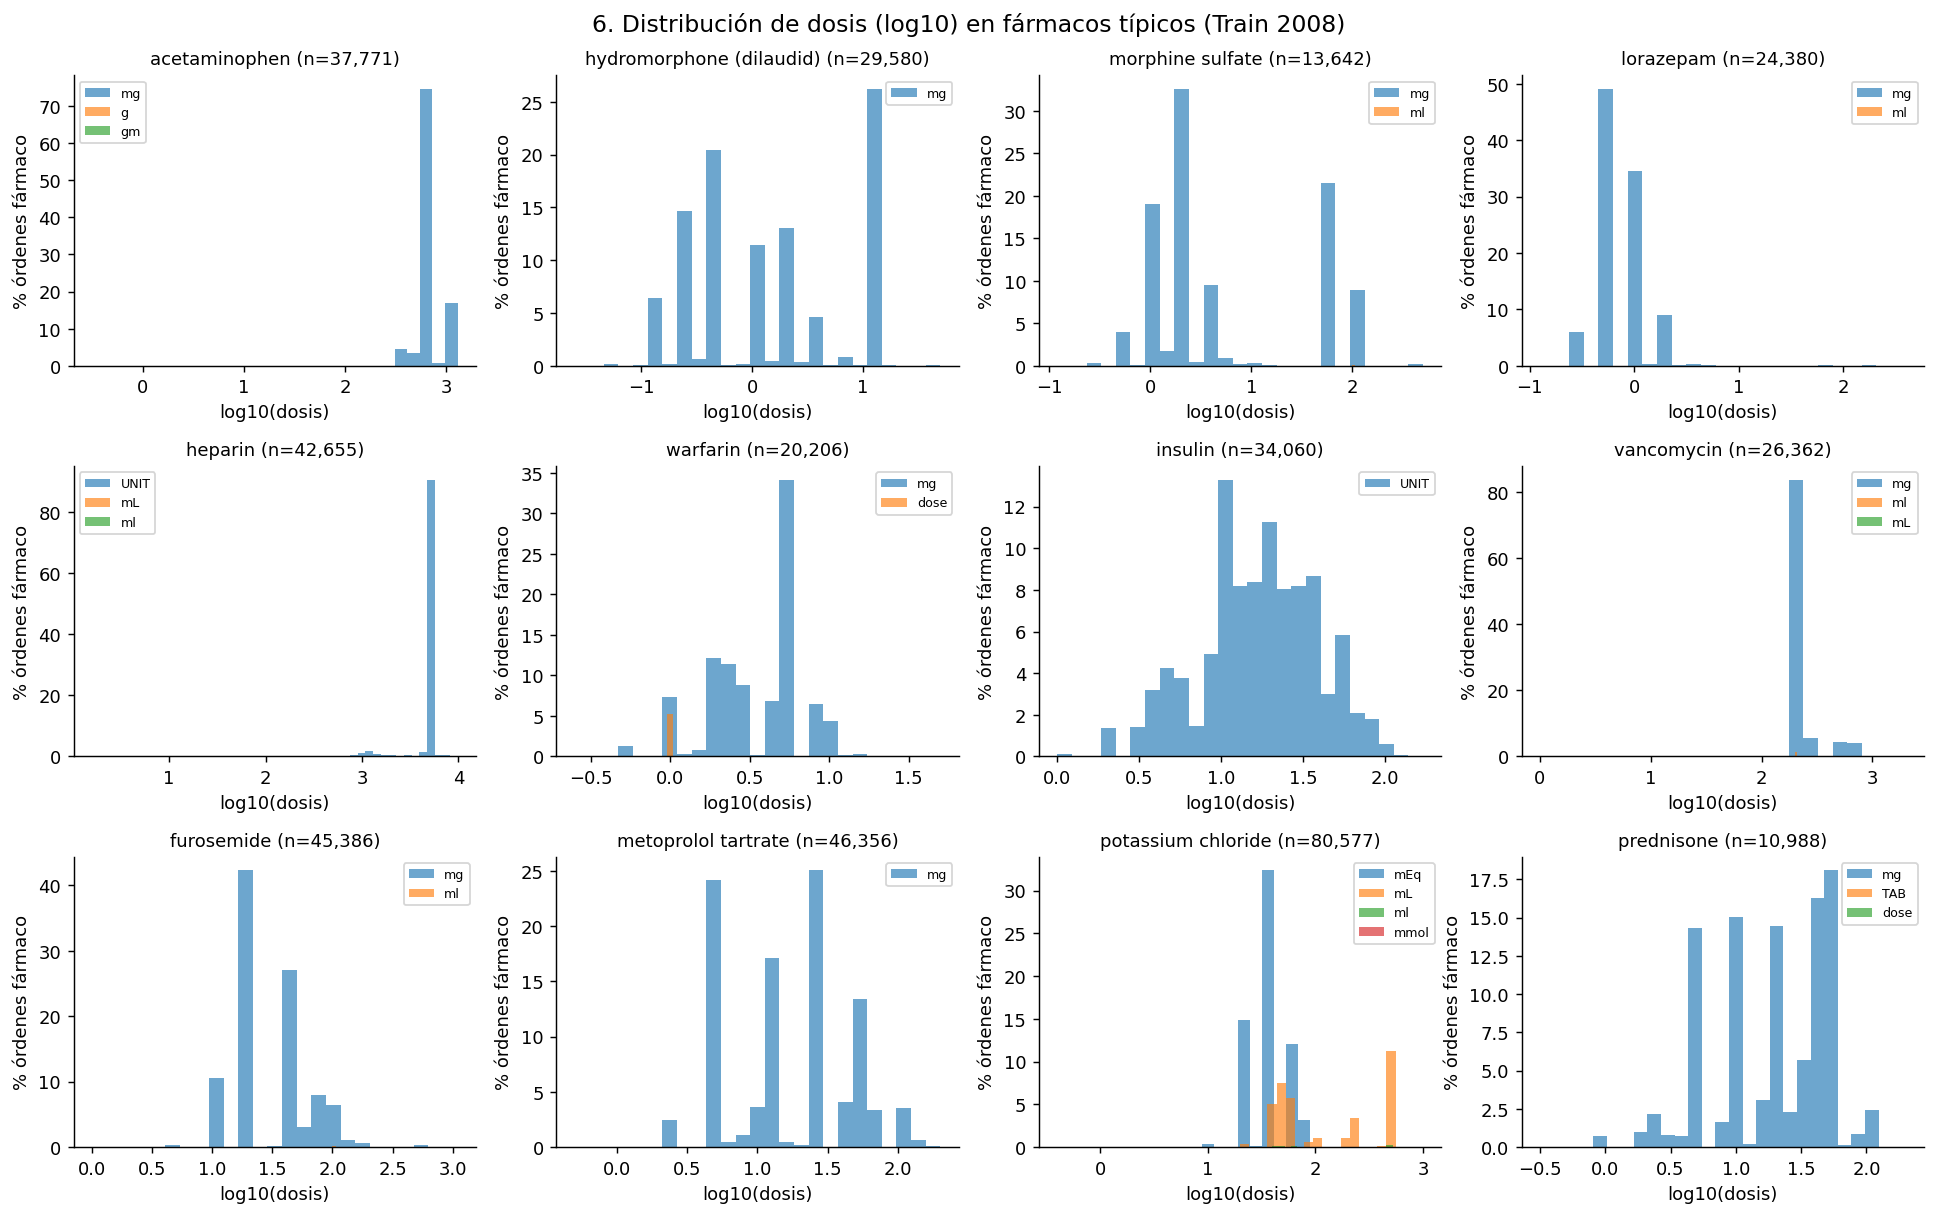

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/06_dosis_farmacos_tipicos.png


In [12]:
# ==============================================================================
# GRÁFICA 6: DOSIS DE FÁRMACOS TÍPICOS (LOG10(DOSIS), COLOR POR UNIDAD)
# ==============================================================================
FARMACOS_TIPICOS = [
    "acetaminophen",
    "hydromorphone (dilaudid)",
    "morphine sulfate",
    "lorazepam",
    "heparin",
    "warfarin",
    "insulin",
    "vancomycin",
    "furosemide",
    "metoprolol tartrate",
    "potassium chloride",
    "prednisone",
]


def resolver_nombre_farmaco(df_ref, objetivo):
  if objetivo in set(df_ref["medication_name"]):
    return objetivo
  candidatos = [
      n for n in df_ref["medication_name"].unique() if n.startswith(objetivo)
  ]
  if candidatos:
    return (
        df_ref[df_ref["medication_name"].isin(candidatos)]["medication_name"]
        .value_counts()
        .index[0]
    )
  return objetivo


resueltos_6 = {f: resolver_nombre_farmaco(df_train, f) for f in FARMACOS_TIPICOS}
print("ℹ️ Mapeo fármacos típicos Gráfica 6:", resueltos_6)

df_pos_tr = df_train[
    (df_train["dose_value"] > 0) & (df_train["dose_unit"].str.len() > 0)
].copy()
df_pos_tr["log10_dosis"] = np.log10(df_pos_tr["dose_value"])

fig, axes = plt.subplots(3, 4, figsize=(15, 9.5))
axes = axes.ravel()

for idx, f_req in enumerate(FARMACOS_TIPICOS):
  ax = axes[idx]
  f_real = resueltos_6[f_req]
  sub = df_pos_tr[df_pos_tr["medication_name"] == f_real]
  if len(sub) == 0:
    ax.set_title(f"{f_req} (sin datos)")
    continue
  top_units = sub["dose_unit"].value_counts().head(4).index
  for u in top_units:
    vals_u = sub[sub["dose_unit"] == u]["log10_dosis"].values
    if len(vals_u) > 0:
      pesos = np.ones_like(vals_u) / len(sub) * 100.0
      ax.hist(vals_u, bins=25, weights=pesos, alpha=0.65, label=u)
  ax.set_title(f"{f_req} (n={len(sub):,})", fontsize=10)
  ax.set_xlabel("log10(dosis)")
  ax.set_ylabel("% órdenes fármaco")
  if len(top_units) > 0:
    ax.legend(fontsize=7, loc="best")

fig.suptitle(
    "6. Distribución de dosis (log10) en fármacos típicos (Train 2008)",
    fontsize=13,
)
guardar_fig("06_dosis_farmacos_tipicos.png")

Algunos fármacos como acetaminophen, heparin o vancomycin se concentran en una única dosis dominante, mientras que la mayoría presenta varios picos marcados correspondientes a distintas presentaciones habituales (como furosemide, lorazepam o metoprolol) e insulin muestra un rango continuo de ajuste. También se aprecia que el cambio de unidad desplaza la escala en fármacos como potassium chloride, por lo que el modelo debe aprender el perfil de dosis por fármaco y unidad en casos como este.

# 7. CONCENTRACIÓN DE LA DOSIS

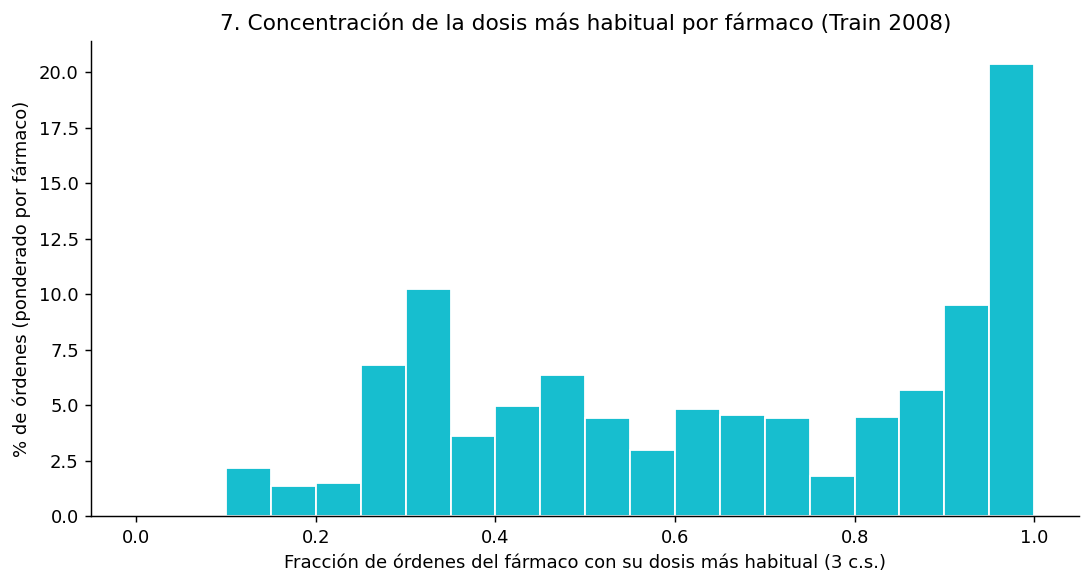

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/07_concentracion_dosis.png


In [8]:
# ==============================================================================
# GRÁFICA 7: CONCENTRACIÓN DE LA DOSIS MÁS HABITUAL (3 CIFRAS SIGNIFICATIVAS)
# ==============================================================================
def sig_figs_3(x):
  if pd.isna(x) or x <= 0:
    return np.nan
  return float(f"{x:.3g}")


df_pos_tr["val_3sf"] = df_pos_tr["dose_value"].apply(sig_figs_3)
df_pos_tr["dosis_key"] = (
    df_pos_tr["val_3sf"].astype(str) + "_" + df_pos_tr["dose_unit"]
)

fraccion_moda_por_med = {}
for med, grp in df_pos_tr.groupby("medication_name"):
  if len(grp) > 0:
    moda_cnt = grp["dosis_key"].value_counts().iloc[0]
    fraccion_moda_por_med[med] = moda_cnt / len(grp)

frac_ord = df_pos_tr["medication_name"].map(fraccion_moda_por_med).dropna()
plt.figure(figsize=(8.5, 4.6))
plt.hist(
    frac_ord.values,
    bins=20,
    range=(0, 1),
    weights=np.ones_like(frac_ord.values) / len(frac_ord.values) * 100.0,
    color="#17becf",
    edgecolor="white",
)
plt.xlabel("Fracción de órdenes del fármaco con su dosis más habitual (3 c.s.)")
plt.ylabel("% de órdenes (ponderado por fármaco)")
plt.title("7. Concentración de la dosis más habitual por fármaco (Train 2008)")
guardar_fig("07_concentracion_dosis.png")

La barra alta a la derecha (0,95–1,0) muestra que un porcentaje importante de las órdenes (en torno al 20 %) corresponde a fármacos con una dosis principal muy dominante, mientras que en la zona media hay fármacos con mayor variedad de dosis. Esto nos viene bien porque en los fármacos muy estables el modelo puede ser más estricto y en los que cambian más habrá que darle más margen.

# 8. REPETICIÓN EN LA HORA ANTERIOR (mismo fármaco y mismo ingreso)

ℹ️ Top 6 fármacos (>=5k órdenes) con mayor repetición (>1 en 1h): {'insulin': np.float64(42.43), 'propofol': np.float64(41.45), 'potassium chloride': np.float64(38.47), 'calcium gluconate': np.float64(36.76), 'bisacodyl': np.float64(31.42), 'morphine sulfate': np.float64(31.22)}


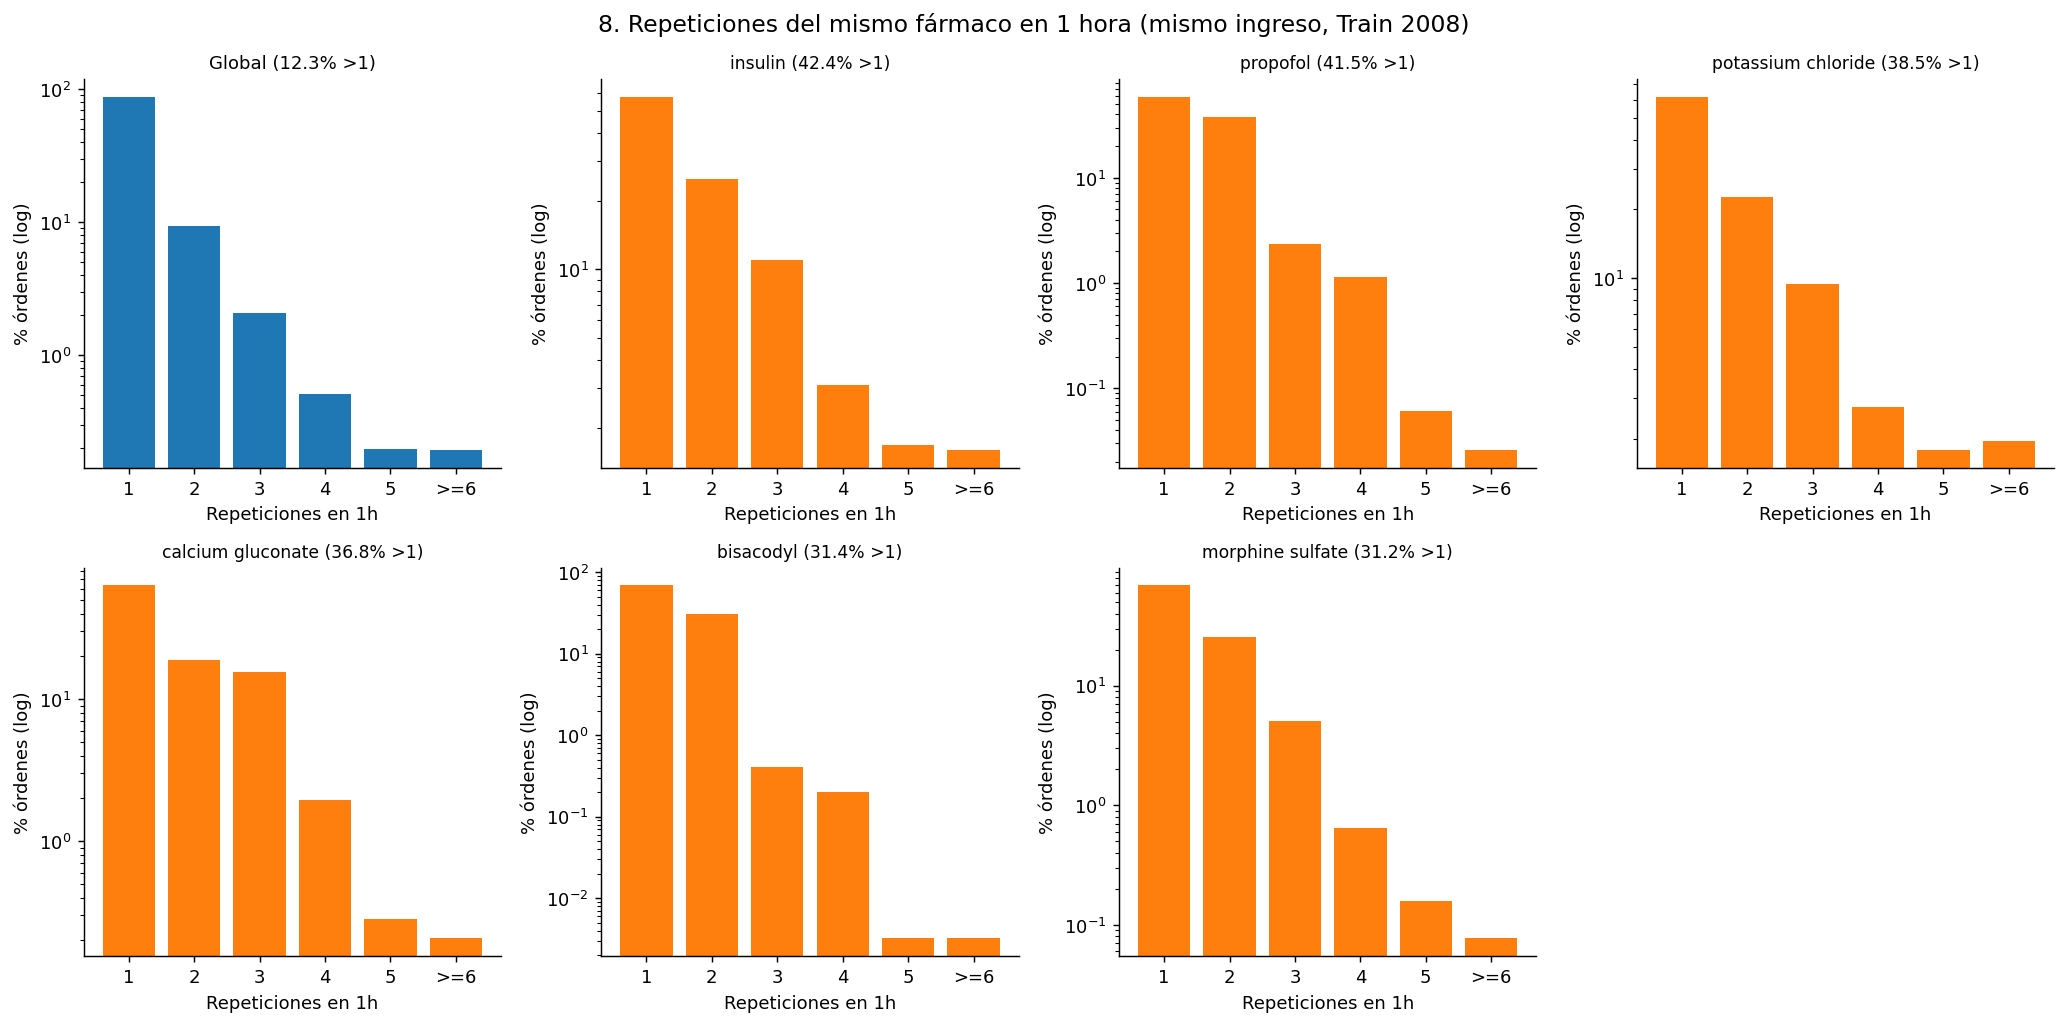

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/08_repeticion_1h.png


In [9]:
# ==============================================================================
# GRÁFICA 8: REPETICIÓN EN 1 HORA (MISMO INGRESO Y FÁRMACO, ESCALA LOG)
# ==============================================================================
def calcular_repeticiones_1h_rapida(df_in):
  df_s = df_in.dropna(subset=["ts"]).copy()
  df_s["ts_ns"] = (
      pd.to_datetime(df_s["ts"], utc=True, errors="coerce")
      .astype("int64")
  )
  df_s = df_s[df_s["ts_ns"] > np.iinfo(np.int64).min].sort_values(
      ["encounter_id", "medication_name", "ts_ns"], kind="mergesort"
  )

  eids = df_s["encounter_id"].to_numpy()
  meds = df_s["medication_name"].to_numpy()
  tns = df_s["ts_ns"].to_numpy()
  n = len(df_s)
  counts = np.ones(n, dtype=np.int32)
  one_hour_ns = 3600 * 1_000_000_000

  left = 0
  for right in range(n):
    while left < right and (
        eids[left] != eids[right]
        or meds[left] != meds[right]
        or (tns[right] - tns[left]) > one_hour_ns
    ):
      left += 1
    counts[right] = right - left + 1

  res = pd.Series(counts, index=df_s.index)
  return res.apply(lambda v: str(v) if v < 6 else ">=6")


rep_tr = calcular_repeticiones_1h_rapida(df_train)
rep_ev = calcular_repeticiones_1h_rapida(df_eval)

df_tr_rep = df_train.loc[rep_tr.index].copy()
df_tr_rep["rep_cat"] = rep_tr.values
df_tr_rep["rep_gt1"] = df_tr_rep["rep_cat"] != "1"

cats_rep = ["1", "2", "3", "4", "5", ">=6"]
pct_rep_global = [
    (df_tr_rep["rep_cat"] == c).mean() * 100.0 for c in cats_rep
]

conteos_med_tr = df_tr_rep["medication_name"].value_counts()
candidatos_5k = conteos_med_tr[conteos_med_tr >= 5000].index
tasa_rep_5k = (
    df_tr_rep[df_tr_rep["medication_name"].isin(candidatos_5k)]
    .groupby("medication_name")["rep_gt1"]
    .mean()
    .sort_values(ascending=False)
)
top6_rep_meds = list(tasa_rep_5k.head(6).index)
print(
    "ℹ️ Top 6 fármacos (>=5k órdenes) con mayor repetición (>1 en 1h):",
    {m: round(tasa_rep_5k[m] * 100, 2) for m in top6_rep_meds},
)

# --- Gráfica 8 ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
axes[0].bar(cats_rep, pct_rep_global, color="#1f77b4")
axes[0].set_yscale("log")
axes[0].set_title(
    f"Global ({df_tr_rep['rep_gt1'].mean()*100:.1f}% >1)", fontsize=10
)
axes[0].set_xlabel("Repeticiones en 1h")
axes[0].set_ylabel("% órdenes (log)")

for i, med in enumerate(top6_rep_meds, start=1):
  sub = df_tr_rep[df_tr_rep["medication_name"] == med]
  pct_m = [(sub["rep_cat"] == c).mean() * 100.0 for c in cats_rep]
  axes[i].bar(cats_rep, pct_m, color="#ff7f0e")
  axes[i].set_yscale("log")
  axes[i].set_title(f"{med} ({tasa_rep_5k[med]*100:.1f}% >1)", fontsize=9.5)
  axes[i].set_xlabel("Repeticiones en 1h")
  axes[i].set_ylabel("% órdenes (log)")

axes[7].axis("off")
fig.suptitle(
    "8. Repeticiones del mismo fármaco en 1 hora (mismo ingreso, Train 2008)",
    fontsize=13,
)
guardar_fig("08_repeticion_1h.png")

En 2008 un 12,3 % de las órdenes tiene más de una prescripción del mismo fármaco y mismo ingreso en la última hora, pero en fármacos como insulin (42,4 %), propofol (41,5 %) o morphine sulfate (31,2 %) ese porcentaje se dispara. Por eso no vale tratar igual una repetición en cualquier medicamento, habrá que ajustar los umbrales de duplicado según el fármaco.

# 9. INTERVALO ENTRE ÓRDENES CONSECUTIVAS

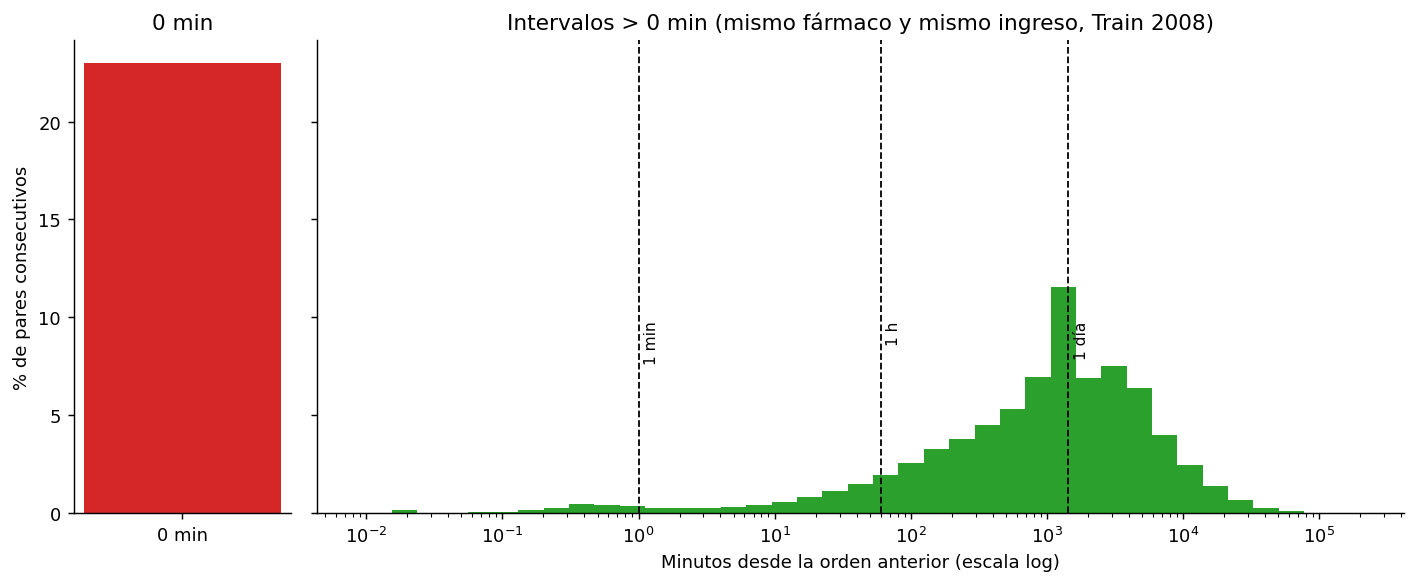

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/09_intervalo_entre_ordenes.png


In [10]:
# ==============================================================================
# GRÁFICA 9 RÁPIDA: INTERVALO ENTRE ÓRDENES CONSECUTIVAS (MINUTOS, LOG + 0 MIN)
# ==============================================================================
def calcular_intervalos_minutos(df_in):
  df_s = df_in.dropna(subset=["ts"]).copy()
  df_s["ts_ns"] = (
      pd.to_datetime(df_s["ts"], utc=True, errors="coerce")
      .astype("int64")
  )
  df_s = df_s[df_s["ts_ns"] > np.iinfo(np.int64).min].sort_values(
      ["encounter_id", "medication_name", "ts_ns"], kind="mergesort"
  )

  eids = df_s["encounter_id"].to_numpy()
  meds = df_s["medication_name"].to_numpy()
  tns = df_s["ts_ns"].to_numpy()

  if len(tns) < 2:
    return np.array([])

  mismo_grupo = (eids[1:] == eids[:-1]) & (meds[1:] == meds[:-1])
  diffs_min = (tns[1:][mismo_grupo] - tns[:-1][mismo_grupo]) / (60.0 * 1e9)
  return diffs_min[diffs_min >= 0]


interv_tr = calcular_intervalos_minutos(df_train)
n_cero = int((interv_tr == 0).sum())
pct_cero = n_cero / len(interv_tr) * 100.0 if len(interv_tr) else 0.0
interv_pos = interv_tr[interv_tr > 0]

bins_min = np.logspace(-2, np.log10(max(interv_pos.max(), 1440)), 40)
pct_pos = np.histogram(interv_pos, bins=bins_min)[0] / len(interv_tr) * 100.0

fig, (ax_zero, ax_log) = plt.subplots(
    1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 5]}, sharey=True
)

ax_zero.bar(["0 min"], [pct_cero], color="#d62728", width=0.5)
ax_zero.set_ylabel("% de pares consecutivos")
ax_zero.set_title("0 min")

ax_log.bar(
    bins_min[:-1],
    pct_pos,
    width=np.diff(bins_min),
    align="edge",
    color="#2ca02c",
    edgecolor="none",
)
ax_log.set_xscale("log")
for marca, etq in [(1, "1 min"), (60, "1 h"), (1440, "1 día")]:
  ax_log.axvline(marca, color="black", linestyle="--", linewidth=1)
  ax_log.text(
      marca * 1.1,
      max(pct_pos) * 0.85 if len(pct_pos) else 1,
      etq,
      rotation=90,
      va="top",
      fontsize=8.5,
  )
ax_log.set_xlabel("Minutos desde la orden anterior (escala log)")
ax_log.set_title("Intervalos > 0 min (mismo fármaco y mismo ingreso, Train 2008)")

guardar_fig("09_intervalo_entre_ordenes.png")

Cerca del 23 % de los pares consecutivos del mismo fármaco y mismo ingreso ocurre en el mismo minuto (0 min), mientras que los intervalos positivos suben hacia 10^3 minutos y alcanzan su mayor pico alrededor de 1 día, propio de pautas diarias.

Como antes de 1 h apenas se acumulan repeticiones frente al tramo de horas y de un día, usar la última hora como ventana en la gráfica 8 parece un corte razonable para captar repeticiones muy seguidas sin mezclar pautas diarias.

# 10. ENTRENAMIENTO 2008 VS EVALUACIÓN 2009 Q1

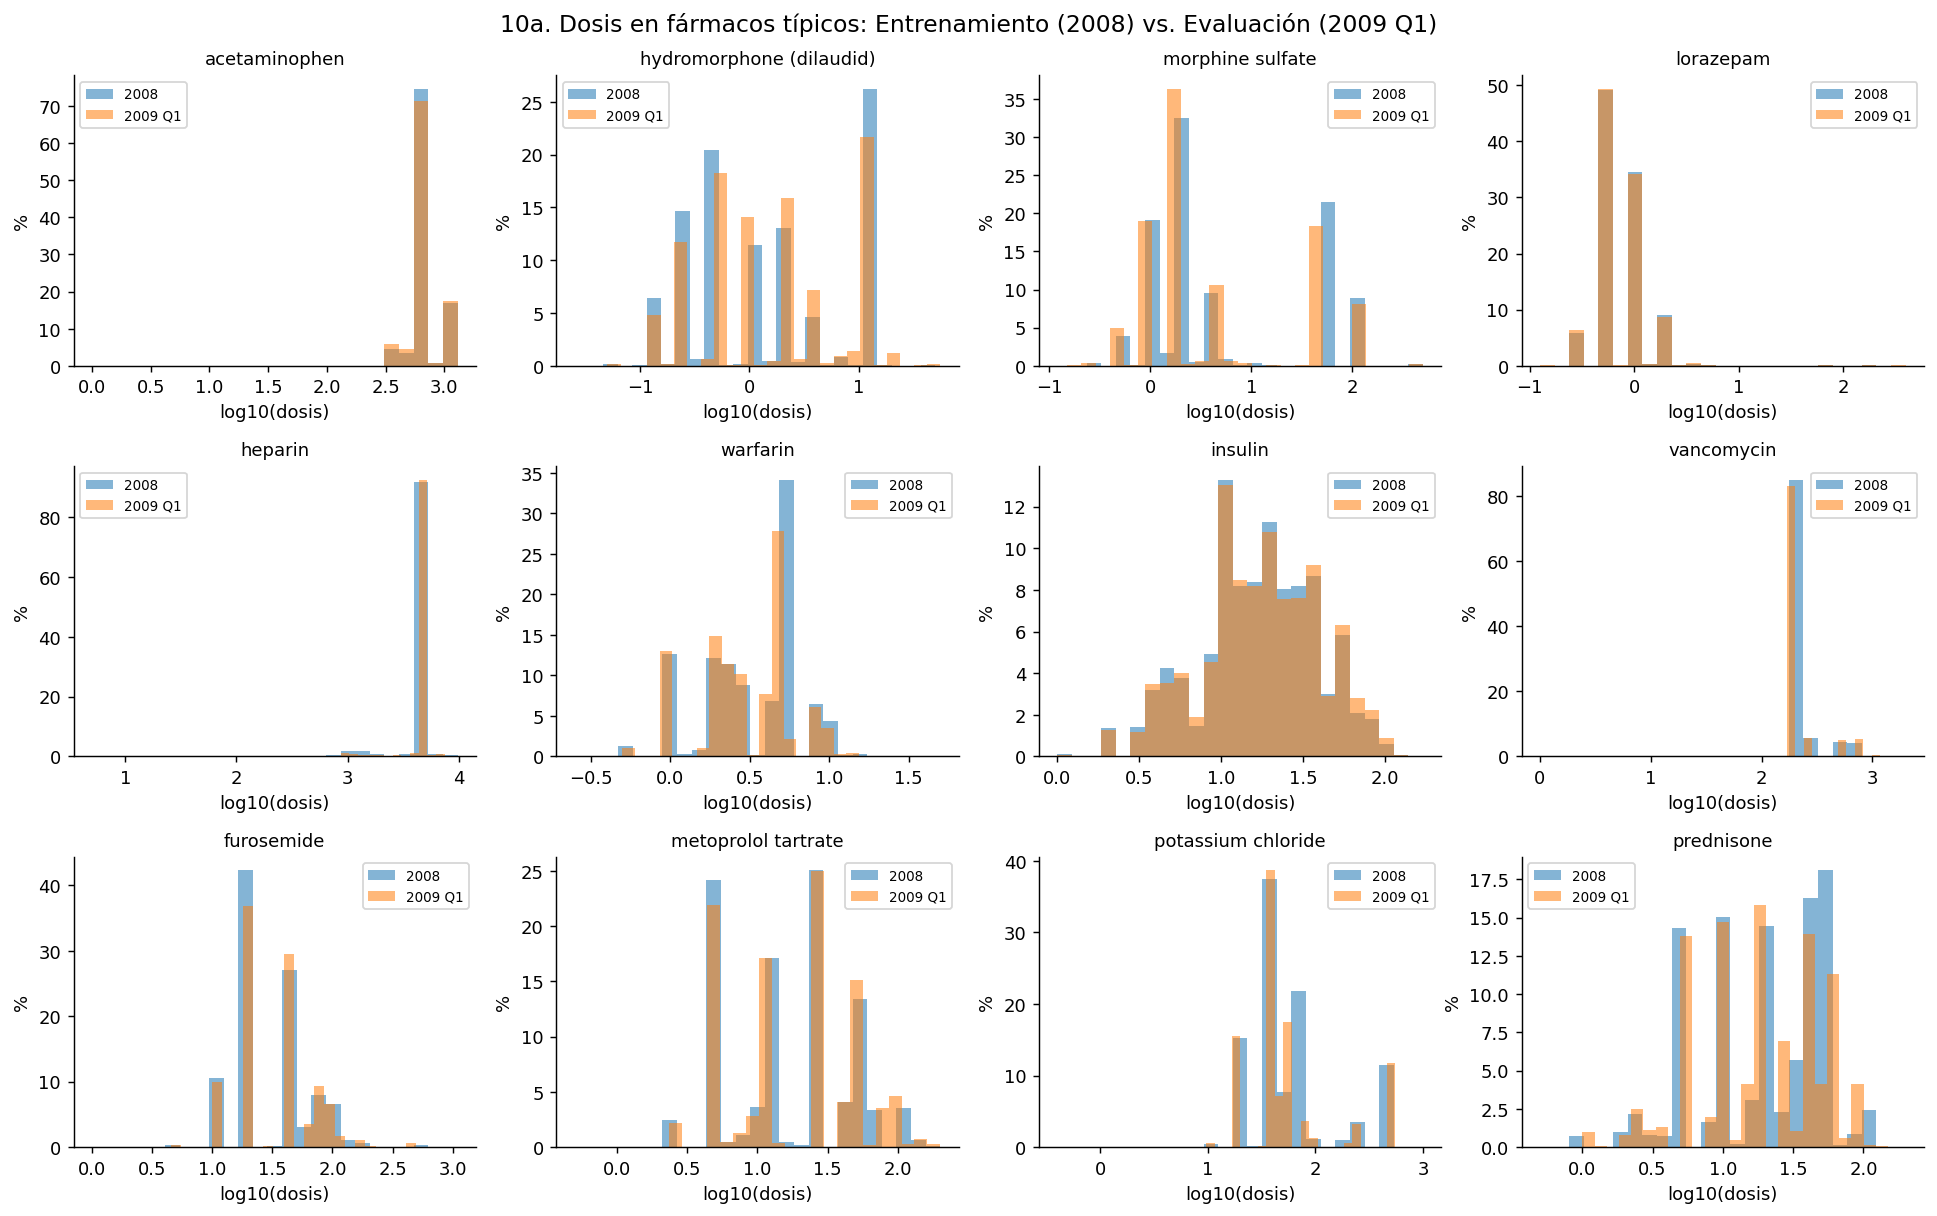

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/10a_comparativa_dosis_train_eval.png


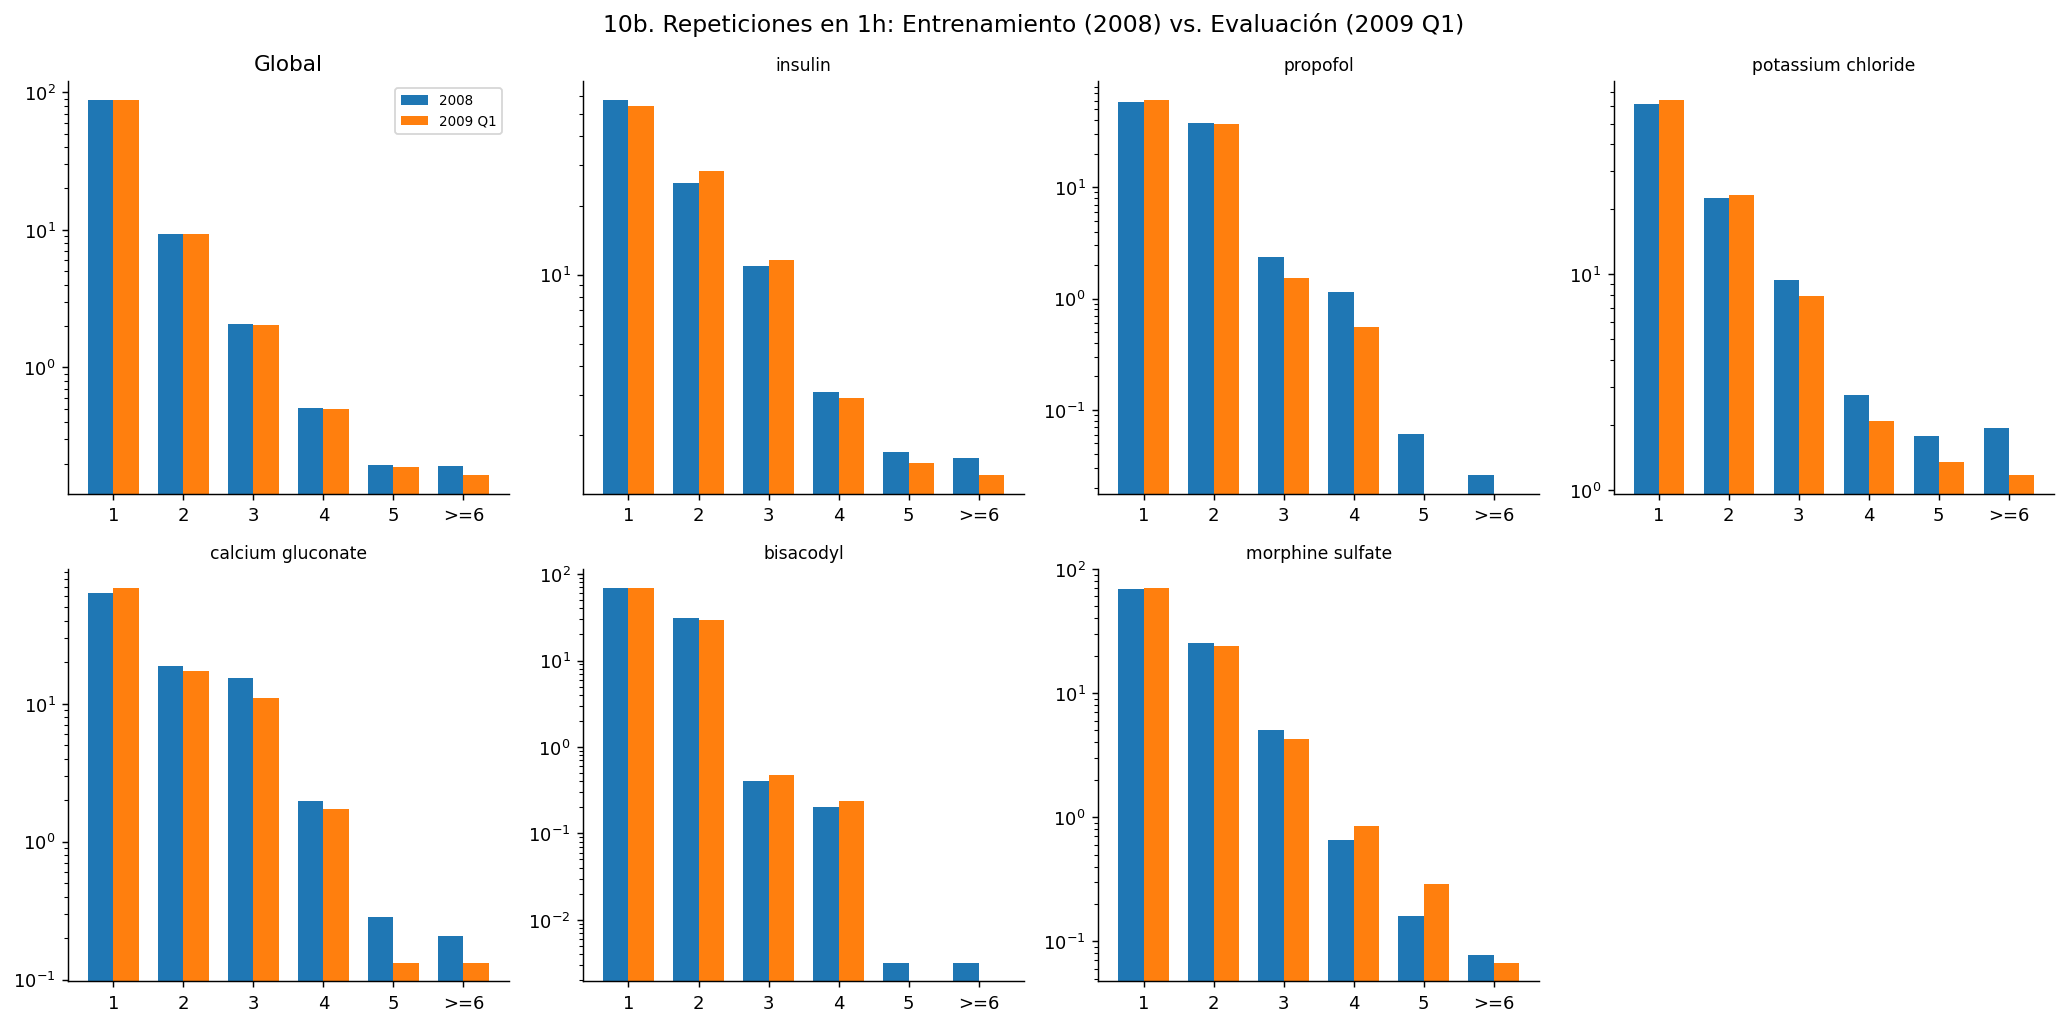

💾 Guardada: /content/drive/MyDrive/TFG/data/figuras_eda/10b_comparativa_repeticion_train_eval.png


In [15]:
# ==============================================================================
# GRÁFICA 10: COMPARATIVA TRAIN (2008) VS EVAL (2009 Q1) EN GRÁFICAS 6 Y 8
# ==============================================================================
df_pos_ev = df_eval[
    (df_eval["dose_value"] > 0) & (df_eval["dose_unit"].str.len() > 0)
].copy()
df_pos_ev["log10_dosis"] = np.log10(df_pos_ev["dose_value"])

fig, axes = plt.subplots(3, 4, figsize=(15, 9.5))
axes = axes.ravel()
for idx, f_req in enumerate(FARMACOS_TIPICOS):
  ax = axes[idx]
  f_real = resueltos_6[f_req]
  v_tr = df_pos_tr[df_pos_tr["medication_name"] == f_real]["log10_dosis"].values
  v_ev = df_pos_ev[df_pos_ev["medication_name"] == f_real]["log10_dosis"].values
  if len(v_tr) > 0:
    ax.hist(
        v_tr,
        bins=25,
        weights=np.ones_like(v_tr) / len(v_tr) * 100.0,
        alpha=0.55,
        label="2008",
        color="#1f77b4",
    )
  if len(v_ev) > 0:
    ax.hist(
        v_ev,
        bins=25,
        weights=np.ones_like(v_ev) / len(v_ev) * 100.0,
        alpha=0.55,
        label="2009 Q1",
        color="#ff7f0e",
    )
  ax.set_title(f_req, fontsize=10)
  ax.set_xlabel("log10(dosis)")
  ax.set_ylabel("%")
  ax.legend(fontsize=7.5)

fig.suptitle(
    "10a. Dosis en fármacos típicos: Entrenamiento (2008) vs. Evaluación (2009 Q1)",
    fontsize=13,
)
guardar_fig("10a_comparativa_dosis_train_eval.png")

# --- Gráfica 10b ---
df_ev_rep = df_eval.loc[rep_ev.index].copy()
df_ev_rep["rep_cat"] = rep_ev.values

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
pct_tr_g = [(df_tr_rep["rep_cat"] == c).mean() * 100.0 for c in cats_rep]
pct_ev_g = [(df_ev_rep["rep_cat"] == c).mean() * 100.0 for c in cats_rep]
x_c = np.arange(len(cats_rep))
axes[0].bar(x_c - 0.18, pct_tr_g, width=0.36, label="2008", color="#1f77b4")
axes[0].bar(x_c + 0.18, pct_ev_g, width=0.36, label="2009 Q1", color="#ff7f0e")
axes[0].set_yscale("log")
axes[0].set_xticks(x_c)
axes[0].set_xticklabels(cats_rep)
axes[0].set_title("Global")
axes[0].legend(fontsize=7.5)

for i, med in enumerate(top6_rep_meds, start=1):
  sub_t = df_tr_rep[df_tr_rep["medication_name"] == med]
  sub_e = df_ev_rep[df_ev_rep["medication_name"] == med]
  pt = [(sub_t["rep_cat"] == c).mean() * 100.0 for c in cats_rep]
  pe = (
      [(sub_e["rep_cat"] == c).mean() * 100.0 for c in cats_rep]
      if len(sub_e) > 0
      else [0] * len(cats_rep)
  )
  axes[i].bar(x_c - 0.18, pt, width=0.36, label="2008", color="#1f77b4")
  axes[i].bar(x_c + 0.18, pe, width=0.36, label="2009 Q1", color="#ff7f0e")
  axes[i].set_yscale("log")
  axes[i].set_xticks(x_c)
  axes[i].set_xticklabels(cats_rep)
  axes[i].set_title(med, fontsize=9.5)

axes[7].axis("off")
fig.suptitle(
    "10b. Repeticiones en 1h: Entrenamiento (2008) vs. Evaluación (2009 Q1)",
    fontsize=13,
)
guardar_fig("10b_comparativa_repeticion_train_eval.png")

Tanto las dosis en escala logarítmica como las repeticiones en una hora mantienen un patrón muy parecido entre 2008 y el primer trimestre de 2009. Esto sugiere que la evaluación en 2009 será una buena manera de testear nuestro modelo debido a la similaridad de los datos entre 2008 y este primer trimestre de 2009.